In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Notebook chal raha hai!")

Notebook chal raha hai!


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/Superstore.csv", encoding="latin-1")
print(df.shape)
print(df.columns.tolist())
df.head()

(9994, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


## 3. Data Cleaning

In [6]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

## 4. Feature Engineering

In [7]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Quarter"] = df["Order Date"].dt.quarter

df[["Order Date", "Year", "Month", "Month Name", "Quarter"]].head()

,Order Date,Year,Month,Month Name,Quarter
0,2016-11-08,2016,11,November,4
1,2016-11-08,2016,11,November,4
2,2016-06-12,2016,6,June,2
3,2015-10-11,2015,10,October,4
4,2015-10-11,2015,10,October,4


## 5. Sales Analysis

**Business Question:** Sales per month ? Sales overall trend ?

In [8]:
monthly_sales = df.groupby(["Year", "Month"])["Sales"].sum().reset_index()

monthly_sales.head(12)

,Year,Month,Sales
0,2014,1,14236.8950
1,2014,2,4519.8920
2,2014,3,55691.0090
3,2014,4,28295.3450
4,2014,5,23648.2870
5,2014,6,34595.1276
6,2014,7,33946.3930
7,2014,8,27909.4685
8,2014,9,81777.3508
9,2014,10,31453.3930


### 5.1 Monthly Sales Trend (Line Chart)

In [9]:
### 5.1 Monthly Sales Trend (Line Chart)

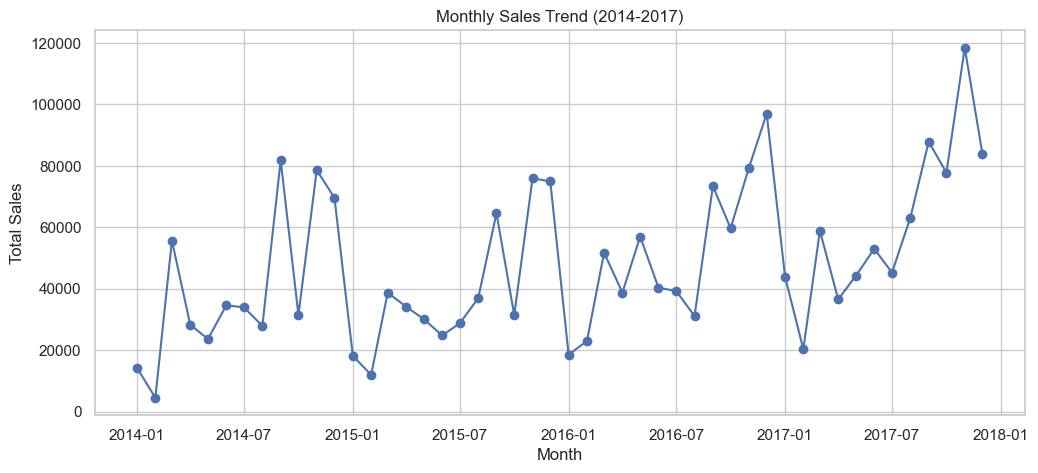

In [10]:
sns.set_theme(style="whitegrid")

monthly_sales["Date"] = pd.to_datetime(monthly_sales[["Year", "Month"]].assign(Day=1))

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Date"], monthly_sales["Sales"], marker="o")
plt.title("Monthly Sales Trend (2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.savefig("../images/monthly_sales_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Sales show an upward trend over the four years, with clear peaks around September to December and dips in January and February every year.

## 6. Time Analysis

In [11]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

month_sales = df.groupby("Month Name")["Sales"].sum().reindex(month_order)

month_sales

Month Name
January       94924.8356
February      59751.2514
March        205005.4888
April        137762.1286
May          155028.8117
June         152718.6793
July         147238.0970
August       159044.0630
September    307649.9457
October      200322.9847
November     352461.0710
December     325293.5035
Name: Sales, dtype: float64

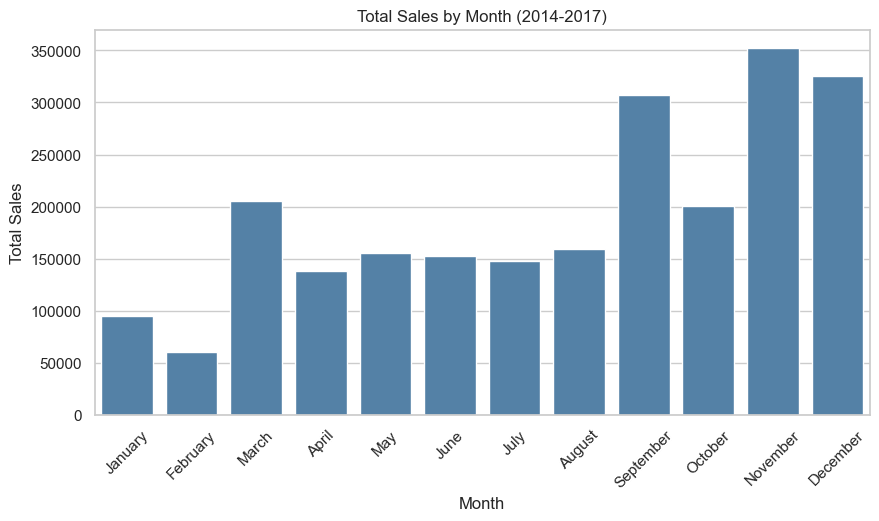

In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(x=month_sales.index, y=month_sales.values, color="steelblue")
plt.title("Total Sales by Month (2014-2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.savefig("../images/sales_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** November, December and September bring in the most sales, while January and February are the weakest months. March also stands out with a smaller spike compared to the months around it.

## 7. Product and Category Analysis

In [13]:
top_products = (df.groupby("Product Name")["Sales"]
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

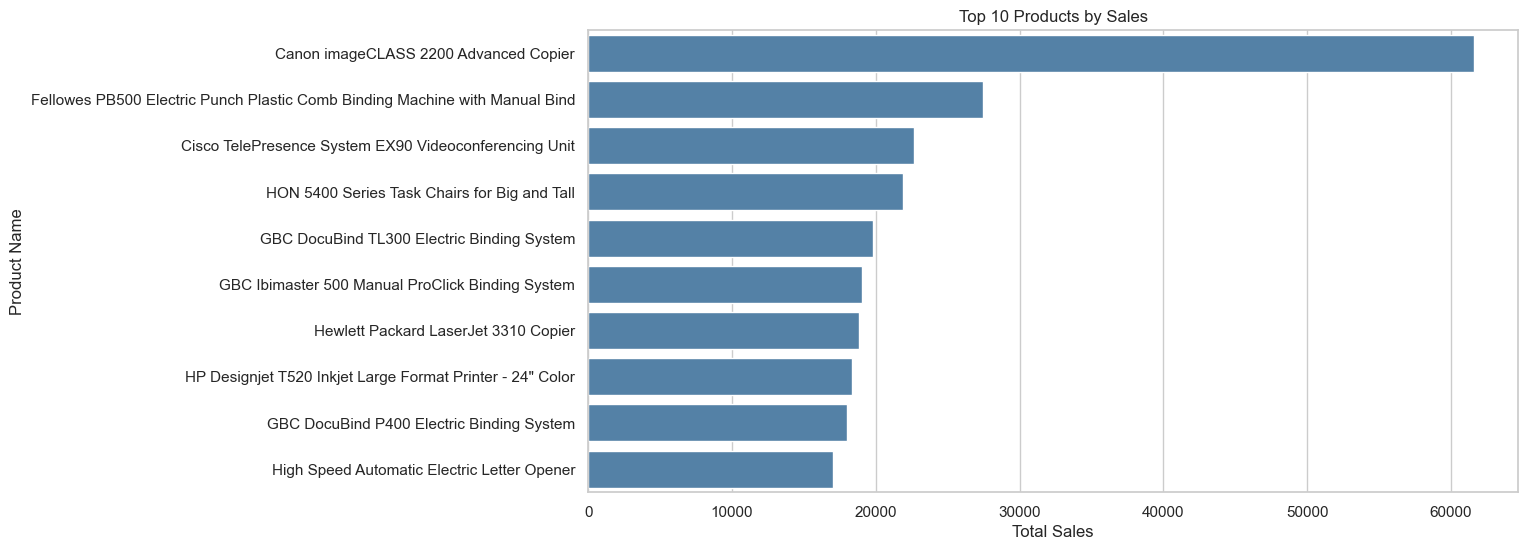

In [14]:
plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index, color="steelblue")
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.savefig("../images/top_products.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The Canon imageCLASS 2200 Advanced Copier is far ahead of every other product in sales. Most of the top 10 are office machines like copiers, binding systems and printers.

In [15]:
category_sales = (df.groupby("Category")["Sales"]
                    .sum()
                    .sort_values(ascending=False))

category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

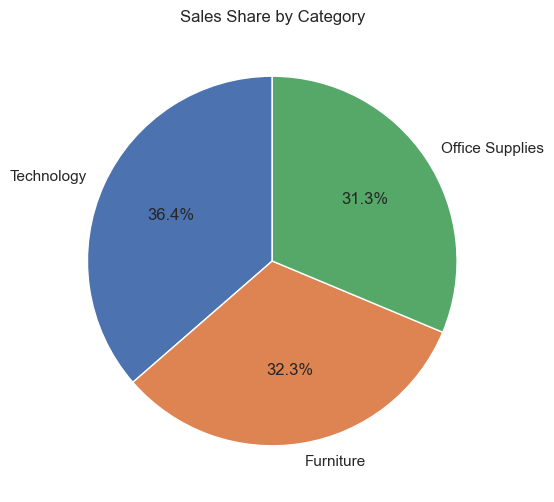

In [16]:
plt.figure(figsize=(6, 6))
plt.pie(category_sales.values,
        labels=category_sales.index,
        autopct="%1.1f%%",
        startangle=90)
plt.title("Sales Share by Category")
plt.savefig("../images/category_share.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Technology generates the highest share of sales at 36.4%, followed by Furniture (32.3%) and Office Supplies (31.3%). The three categories are fairly close, so sales are spread out quite evenly.

## 8. Customer Analysis

In [17]:
top_customers = (df.groupby("Customer Name")["Sales"]
                   .sum()
                   .sort_values(ascending=False)
                   .head(10))

top_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

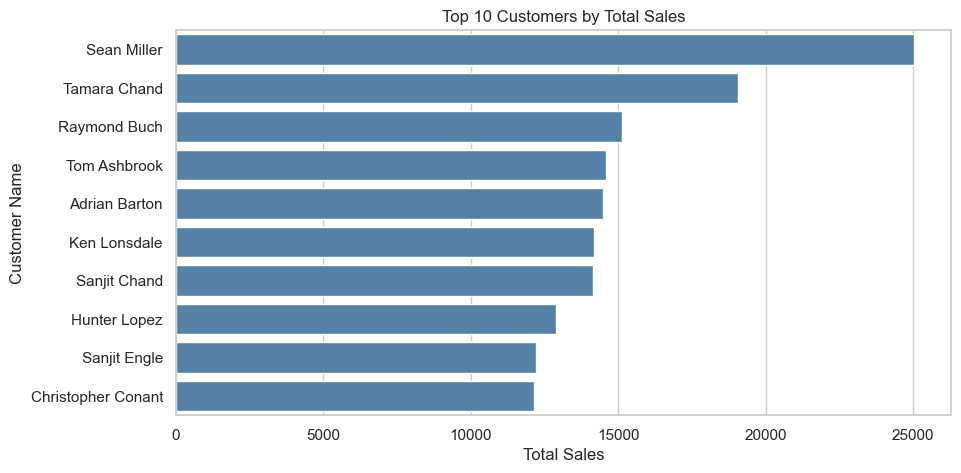

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_customers.values, y=top_customers.index, color="steelblue")
plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.savefig("../images/top_customers.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Sean Miller is the top customer with about 25k in total sales, followed by Tamara Chand. The top 10 customers together account for only around 7% of total sales, so revenue is spread across many customers rather than a few big ones.

## 9. Region Analysis

In [19]:
region_sales = (df.groupby("Region")["Sales"]
                  .sum()
                  .sort_values(ascending=False))

region_sales

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64

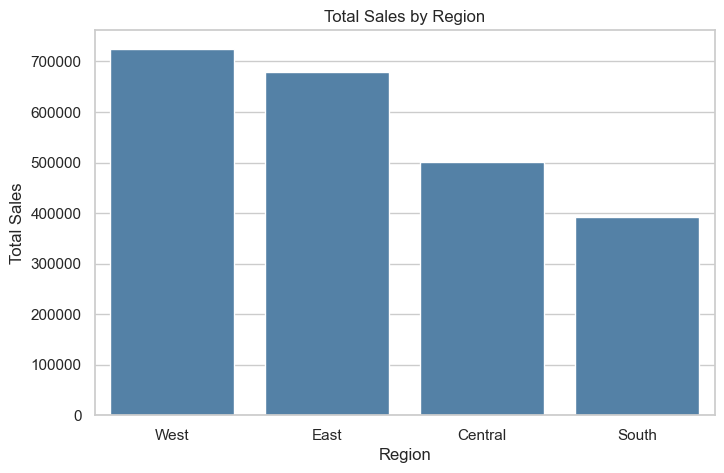

In [20]:
plt.figure(figsize=(8, 5))
sns.barplot(x=region_sales.index, y=region_sales.values, color="steelblue")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.savefig("../images/sales_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The West region generates the most sales, followed closely by the East. Together they account for roughly 61% of total sales, while the South is the weakest region.

In [21]:
top_states = (df.groupby("State")["Sales"]
                .sum()
                .sort_values(ascending=False)
                .head(10))

top_states

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64

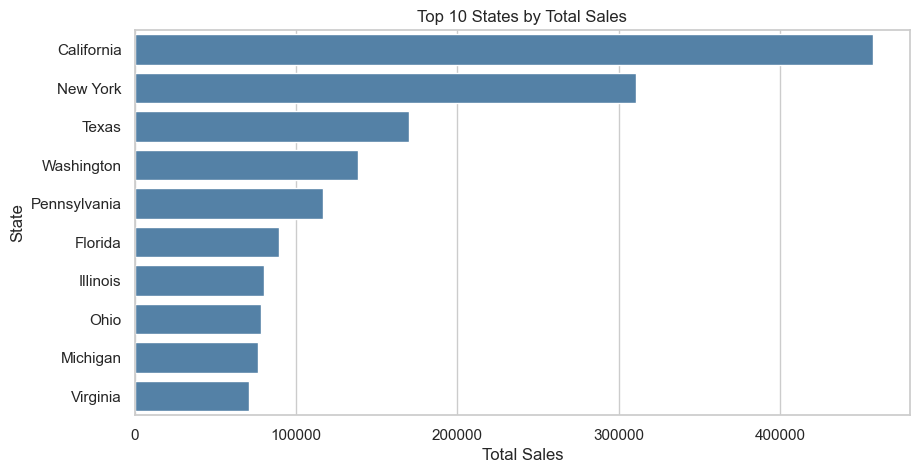

In [22]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_states.values, y=top_states.index, color="steelblue")
plt.title("Top 10 States by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.savefig("../images/top_states.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** California and New York lead by a wide margin, and the top 10 states together bring in around 69% of total sales. This matches the region view, since California is in the West and New York is in the East.

## 10. Order Analysis

In [23]:
order_sales = df.groupby("Order ID")["Sales"].sum()

order_sales.describe()

count     5009.000000
mean       458.614666
std        954.730953
min          0.556000
25%         37.630000
50%        151.960000
75%        512.064000
max      23661.228000
Name: Sales, dtype: float64

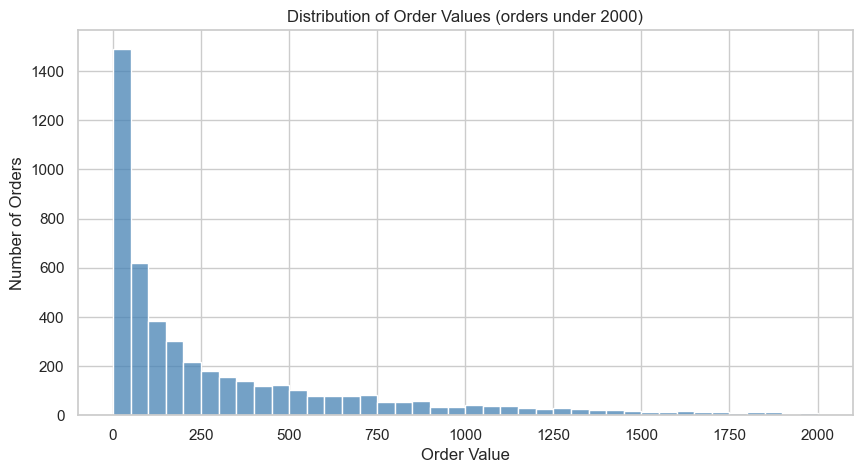

In [24]:
plt.figure(figsize=(10, 5))
sns.histplot(order_sales[order_sales < 2000], bins=40, color="steelblue")
plt.title("Distribution of Order Values (orders under 2000)")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.savefig("../images/order_value_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The average order value is about 459, but the median is only about 152. Most orders are small, and a few very large orders pull the average up. (Chart shows orders under 2000 only, so the largest orders are left out for readability.)

## 11. Correlation Analysis

In [25]:
corr = df[["Sales", "Quantity", "Discount", "Profit"]].corr()

corr

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


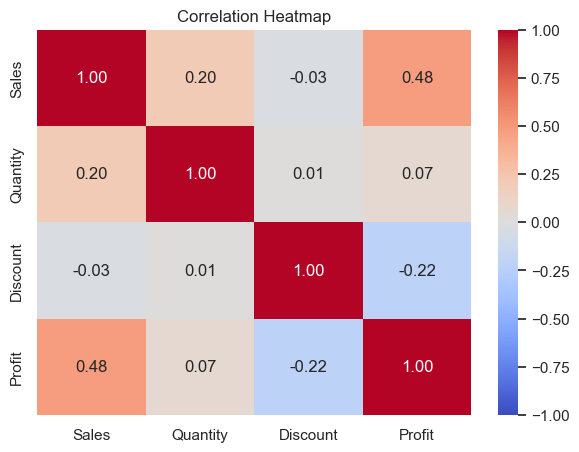

In [26]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.savefig("../images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Quantity has only a weak relationship with sales (0.20), so a higher quantity does not always mean higher revenue. Sales and profit are moderately related (0.48), while discount and profit show a weak negative relation (-0.22).

## 12. Low Performing Products

In [27]:
bottom_products = (df.groupby("Product Name")["Sales"]
                     .sum()
                     .sort_values(ascending=True)
                     .head(10))

bottom_products

Product Name
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Avery 5                                                             5.760
Xerox 20                                                            6.480
Grip Seal Envelopes                                                 7.072
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                  7.700
Avery Hi-Liter Comfort Grip Fluorescent Highlighter, Yellow Ink     7.800
Xerox 1989                                                          7.968
4009 Highlighters                                                   8.040
Stockwell Gold Paper Clips                                          8.096
Newell 308                                                          8.400
Name: Sales, dtype: float64

In [28]:
bottom_check = (df[df["Product Name"].isin(bottom_products.index)]
                  .groupby("Product Name")
                  .agg(Total_Sales=("Sales", "sum"),
                       Orders=("Order ID", "nunique"),
                       Category=("Category", "first"))
                  .sort_values("Total_Sales"))

bottom_check

,Total_Sales,Orders,Category
Product Name,,,
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac,1.624,1,Office Supplies
Avery 5,5.760,1,Office Supplies
Xerox 20,6.480,1,Office Supplies
Grip Seal Envelopes,7.072,1,Office Supplies
Avery Hi-Liter Pen Style Six-Color Fluorescent Set,7.700,1,Office Supplies
"Avery Hi-Liter Comfort Grip Fluorescent Highlighter, Yellow Ink",7.800,2,Office Supplies
Xerox 1989,7.968,1,Office Supplies
4009 Highlighters,8.040,1,Office Supplies
Stockwell Gold Paper Clips,8.096,2,Office Supplies


**Observation:** The 10 lowest-selling products are all Office Supplies, but each was ordered only once or twice. So they are rarely ordered rather than consistently low performers. A better check is to look at products with a decent number of orders.

In [29]:
product_stats = (df.groupby("Product Name")
                   .agg(Total_Sales=("Sales", "sum"),
                        Orders=("Order ID", "nunique")))

product_stats[product_stats["Orders"] >= 5].sort_values("Total_Sales").head(10)

,Total_Sales,Orders
Product Name,,
Maxell 4.7GB DVD+R 5/Pack,11.682,5
"OIC Binder Clips, Mini, 1/4"" Capacity, Black",15.624,5
Insertable Tab Indexes For Data Binders,17.490,5
Maxell 4.7GB DVD-R 5/Pack,19.008,5
BIC Brite Liner Grip Highlighters,24.272,5
Colored Push Pins,24.978,5
Bagged Rubber Bands,25.704,5
"Avery Triangle Shaped Sheet Lifters, Black, 2/Pack",25.830,6
Avery Reinforcements for Hole-Punch Pages,28.512,8


**Observation:** Among products ordered at least 5 times, the lowest sellers are cheap items like binder clips, rubber bands, push pins and highlighters. They sell repeatedly but bring in very little revenue per order because of their low price.

In [30]:
top_quantity = (df.groupby("Product Name")["Quantity"]
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

top_quantity

Product Name
Staples                                                       215
Staple envelope                                               170
Easy-staple paper                                             150
Staples in misc. colors                                        86
KI Adjustable-Height Table                                     74
Avery Non-Stick Binders                                        71
Storex Dura Pro Binders                                        71
GBC Premium Transparent Covers with Diagonal Lined Pattern     67
Situations Contoured Folding Chairs, 4/Set                     64
Staple-based wall hangings                                     62
Name: Quantity, dtype: int64

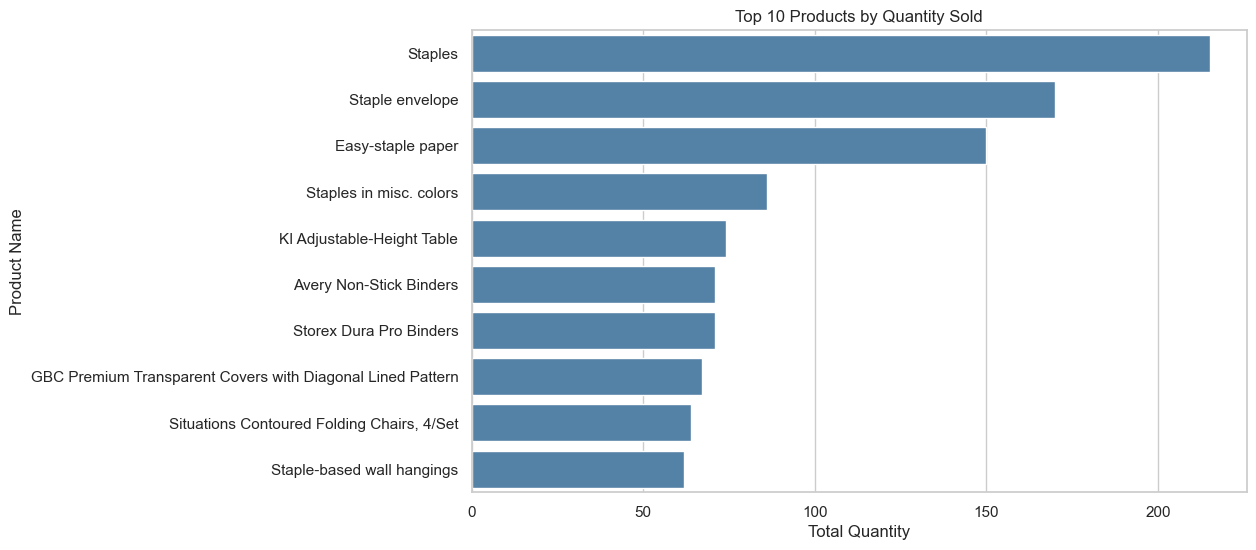

In [31]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_quantity.values, y=top_quantity.index, color="steelblue")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity")
plt.ylabel("Product Name")
plt.savefig("../images/top_products_by_quantity.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The products sold in the highest quantities are mostly cheap items like staples, binders and covers. None of them appear in the top 10 by sales, so high quantity does not necessarily mean high revenue.

## 13. Saving the Cleaned Data

In [32]:
df.to_csv("../data/cleaned/superstore_cleaned.csv", index=False)

## 14. Conclusion

**Key findings from the Superstore data (2014-2017, 9,994 rows):**

- **Sales trend:** Monthly sales grow over the four years. September, November and December are the peak months (November is highest at about 352k in total), while January and February are the weakest.
- **Category:** Technology brings the most revenue (36.4%), followed by Furniture (32.3%) and Office Supplies (31.3%). The split is fairly even.
- **Products:** The Canon imageCLASS 2200 Advanced Copier leads in sales by a wide margin. Products sold in the highest quantities (staples, binders) are cheap and do not appear in the top 10 by sales.
- **Customers:** The top 10 customers make up only about 7% of total sales, so revenue is spread across many customers.
- **Region:** West (31.6%) and East (29.5%) together give around 61% of sales. California and New York are the leading states.
- **Orders:** Average order value is about 459, but the median is only about 152, because a few very large orders pull the average up.
- **Relationships:** Quantity and sales have only a weak correlation (0.20), and discount has a weak negative relation with profit (-0.22).

**Limitations:**
- The dataset covers only the United States, so the analysis is by region and state instead of country.
- Low-selling products were checked only by total sales and order count, not year by year.